# Paper 07: MobileNetV2: Inverted Residuals and Linear Bottlenecks
**Authors**: Mark Sandler, Andrew Howard, Menglong Zhu, Andrey Zhmoginov, Liang-Chieh Chen (2018)

---

## 1. The Historical Breaking Point: The Edge Robotics Crisis
By 2017, standard vision models like ResNet-50 were too heavy ($3.8$ GFLOPs, 25M params) for mobile robots, drones, and embedded controllers.

- **Depthwise Separable Convolutions (MobileNetV1)**: Separated spatial filtering (depthwise $3\times 3$) from channel mixing (pointwise $1\times 1$), slashing computation by $8\times$ to $9\times$.
- **The Fatal Flaw of MobileNetV1**: Applying non-linear activations (ReLU) in narrow low-dimensional channels causes severe **manifold collapse**; negative values are permanently zeroed out, destroying valuable features.

## 2. The First-Principles Solution: Inverted Residuals & Linear Bottlenecks
Sandler et al. introduced two foundational insights:
1. **Inverted Residuals**: Instead of compressing channels in the bottleneck (like ResNet), **expand channels by $6\times$** into a high-dimensional space, perform depthwise spatial filtering there, and project back to a compact bottleneck.
2. **Linear Bottlenecks**: **Never apply ReLU to the final low-dimensional projection!** Keeping the projection linear preserves the manifold's information capacity.

In this notebook, you will test `InvertedResidual` and `MobileNetV2` implemented in `model.py`.

---
## Setup
`%autoreload 2` automatically reloads your code from `model.py` whenever changes are saved.

In [8]:
%load_ext autoreload
%autoreload 2

import time
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from model import ConvBNReLU, InvertedResidual, MobileNetV2, mobilenet_v2
from core.models import resnet18
from core.optimizers import AdamW
import tests

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Part 1: InvertedResidual & Linear Bottleneck Verification

We verify:
1. `InvertedResidual` with stride 1 activates the residual shortcut.
2. `InvertedResidual` with stride 2 correctly downsamples without shortcut connection.
3. **Linear Bottleneck**: Confirms that the final projection layer is strictly linear (no ReLU), preventing manifold collapse.

In [18]:
print("Testing InvertedResidual (Stride 1):")
tests.test_inverted_residual_stride1(InvertedResidual)

print("\nTesting InvertedResidual (Stride 2):")
tests.test_inverted_residual_stride2(InvertedResidual)

print("\nTesting Linear Bottleneck (No ReLU on Bottleneck):")
tests.test_linear_bottleneck_no_relu(InvertedResidual)

Testing InvertedResidual (Stride 1):
  [PASS] InvertedResidual (stride=1, expand=6) preserves shape and activates shortcut connection!

Testing InvertedResidual (Stride 2):
  [PASS] InvertedResidual (stride=2, expand=6) correctly downsamples (28x28 -> 14x14) without shortcut!

Testing Linear Bottleneck (No ReLU on Bottleneck):
  [PASS] Linear Bottleneck verified: final projection has no ReLU (preserves low-dim manifold)!


True

---
## Part 2: Full Architecture & Overfit Gate

We verify:
1. Full MobileNetV2 forward pass on standard ImageNet resolution $(B, 3, 224, 224) \to (B, 1000)$.
2. Custom classification/policy head $(B, 10)$.
3. **Single-Batch Overfit Gate**: Rapid convergence on a toy classification batch.

In [20]:
print("Testing MobileNetV2 Full Architecture:")
tests.test_mobilenet_v2_shapes(mobilenet_v2)

print("\nTesting Single-Batch Overfit Gate:")
tests.test_single_batch_overfit(mobilenet_v2)

Testing MobileNetV2 Full Architecture:
  [PASS] MobileNetV2 forward pass output matches (B, 1000)!
  [PASS] MobileNetV2 forward pass with custom classes matches (B, 10)!

Testing Single-Batch Overfit Gate:
  [PASS] Single-batch overfit gate passed (loss: 1.5074 -> 0.000245)!


True

---
## Part 3: Edge Robotics Benchmark: MobileNetV2 vs ResNet-18

We compare:
1. **Parameter Efficiency**: MobileNetV2 parameters vs ResNet-18.
2. **Forward Inference Latency**: Execution time for 100 forward passes on $(16, 3, 224, 224)$ batches.

Notice how MobileNetV2 achieves dramatic parameter savings while maintaining competitive representation power!

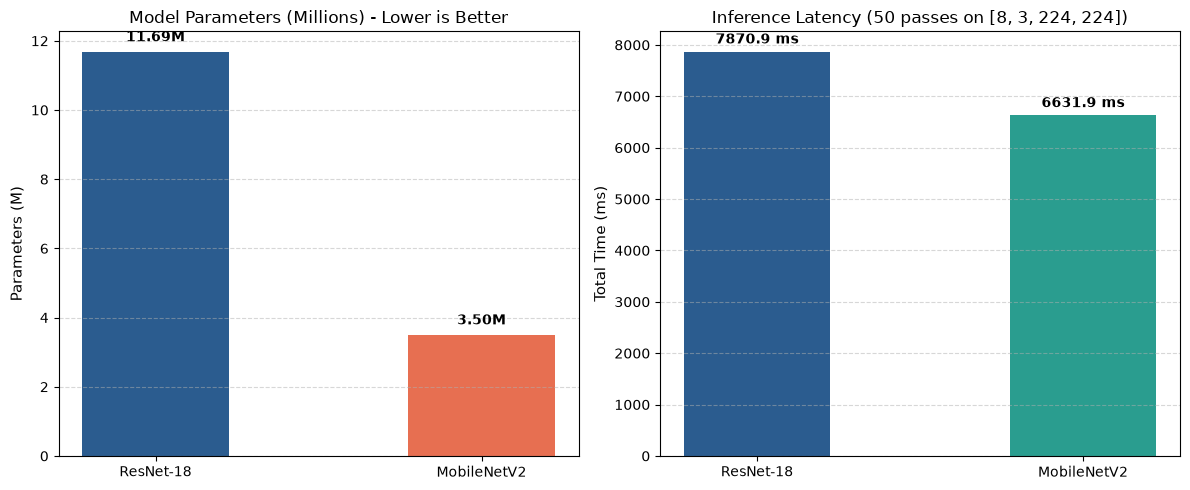

ResNet-18: 11.69M params | MobileNetV2: 3.50M params (Savings: 70.0%)


In [21]:
torch.manual_seed(42)

m_v2 = mobilenet_v2(num_classes=1000)
m_res = resnet18(num_classes=1000)

params_v2 = sum(p.numel() for p in m_v2.parameters()) / 1e6
params_res = sum(p.numel() for p in m_res.parameters()) / 1e6

bench_x = torch.randn(8, 3, 224, 224)
m_v2.eval()
m_res.eval()

# Warmup
with torch.no_grad():
    for _ in range(10):
        _ = m_v2(bench_x)
        _ = m_res(bench_x)

iters = 50
t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(iters):
        _ = m_res(bench_x)
t_res = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(iters):
        _ = m_v2(bench_x)
t_v2 = (time.perf_counter() - t0) * 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Parameters Plot
bars1 = ax1.bar(['ResNet-18', 'MobileNetV2'], [params_res, params_v2], color=['#2b5c8f', '#e76f51'], width=0.45)
ax1.set_title('Model Parameters (Millions) - Lower is Better', fontsize=12)
ax1.set_ylabel('Parameters (M)', fontsize=11)
ax1.grid(True, axis='y', linestyle='--', alpha=0.5)
for b in bars1:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3, f'{b.get_height():.2f}M', ha='center', fontweight='bold')

# Latency Plot
bars2 = ax2.bar(['ResNet-18', 'MobileNetV2'], [t_res, t_v2], color=['#2b5c8f', '#2a9d8f'], width=0.45)
ax2.set_title(f'Inference Latency ({iters} passes on [8, 3, 224, 224])', fontsize=12)
ax2.set_ylabel('Total Time (ms)', fontsize=11)
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)
for b in bars2:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + (max(t_res, t_v2) * 0.02), f'{b.get_height():.1f} ms', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"ResNet-18: {params_res:.2f}M params | MobileNetV2: {params_v2:.2f}M params (Savings: {(1 - params_v2/params_res)*100:.1f}%)")